# NQ Intraday Breakout — backtest

The engine lives in the [`nq_breakout`](src/nq_breakout) package; this notebook
only loads data, runs it and reports. Rules were frozen in 2022 (original
MultiCharts strategy); the Python engine is a 2025 port, not yet validated
trade-by-trade against the original.

**The cells below run the corrected conventions with stop fills.** That is one
of three configurations the README reports, not the single answer. The same
rules on the same data give Sharpe 0.95 under the original notebook's
conventions and 1.11 under corrected conventions with close fills — and most of
that spread comes from the entry-fill assumption, which is still unresolved.
See [`docs/bias-audit.md`](docs/bias-audit.md) for the twelve differences one at
a time, and run `tools/bias_attribution.py` to reproduce the whole chain.

Before trusting any number, read the **data diagnostics** cell output: it checks
the feed's timezone, roll splicing and overnight gap exposure.

In [1]:
import pandas as pd
from dataclasses import replace
from nq_breakout import (Config, load_nq_1min, load_qqq, resample_5min,
                         run_data_diagnostics, run_backtest, metrics_table,
                         format_metrics, align_benchmark, trade_pnl_tstat)
from nq_breakout.plots import plot_backtest, plot_vs_benchmark

BASE = Config()  # risk 1%, entry_mode='stop' — see backtest.Config for every knob
BASE

Config(point_value=20.0, tick_size=0.25, tick_value=5.0, stop_dollars=2000.0, target_dollars=4000.0, initial_capital=1000000.0, margin_per_contract=23282.57, margin_buffer=0.15, risk_pct=0.01, commission_per_side=2.5, slippage_ticks_per_side=1.5, window_start=datetime.time(8, 30), window_end=datetime.time(10, 0), trade_start=datetime.time(10, 0), trade_end=datetime.time(14, 30), regular_start=datetime.time(9, 30), regular_end=datetime.time(16, 0), max_trades_per_day=2, max_long_hold_days=5, entry_mode='stop')

In [2]:
nq_1min = load_nq_1min('Data/nq-10y-1min.csv')
qqq = load_qqq('Data/QQQ_daily.csv')
df_5min = resample_5min(nq_1min)

run_data_diagnostics(nq_1min, BASE)

== Timezone check ==
Largest average-volume jump starts at 08:30:00 (x6.4 vs the previous half hour).

== Roll / splice check ==
Median |overnight gap|: 0.25 pts. Gaps beyond 20 pts: 174 (57 in quarterly roll months).
day
2025-02-02   -371.00
2022-02-22   -366.50
2022-02-27   -287.50
2020-03-01   -198.75
2020-03-29   -165.25
2022-07-05    149.00
2022-06-21    147.50
2018-12-06   -141.00
2025-01-02    136.75
2025-01-26   -136.75

== Overnight gap risk ==
Sessions opening more than 100 pts (the stop distance) away from the prior close: 20 of 3101 (0.6%).
The feed averages 1098 bars/day — consistent with near-continuous Globex coverage. run_backtest walks every bar, including overnight ones, so stops/targets are caught at the exact crossing rather than approximated by these opening gaps.


In [3]:
bt_1pct = run_backtest(df_5min, replace(BASE, risk_pct=0.01))
bt_2pct = run_backtest(df_5min, replace(BASE, risk_pct=0.02))
bt_legacy = run_backtest(df_5min, replace(BASE, risk_pct=0.01, entry_mode='close'))

for name, bt in [('1% risk, stop entry ', bt_1pct),
                 ('2% risk, stop entry ', bt_2pct),
                 ('1% risk, close entry', bt_legacy)]:
    t = bt.trades
    stats = trade_pnl_tstat(t)
    print(f"{name}: {len(t):5d} trades | net PnL {t['pnl'].sum():14,.0f} | "
          f"avg contracts {t['contracts'].mean():6.2f} | "
          f"PnL/contract {stats['mean']:8.2f} (t-stat {stats['t_stat']:.2f})")

1% risk, stop entry :  1725 trades | net PnL      2,800,810 | avg contracts   8.92 | PnL/contract   176.94 (t-stat 3.24)
2% risk, stop entry :  1725 trades | net PnL     12,069,455 | avg contracts  39.65 | PnL/contract   176.94 (t-stat 3.24)
1% risk, close entry:  1736 trades | net PnL      3,323,800 | avg contracts   8.94 | PnL/contract   190.05 (t-stat 3.49)


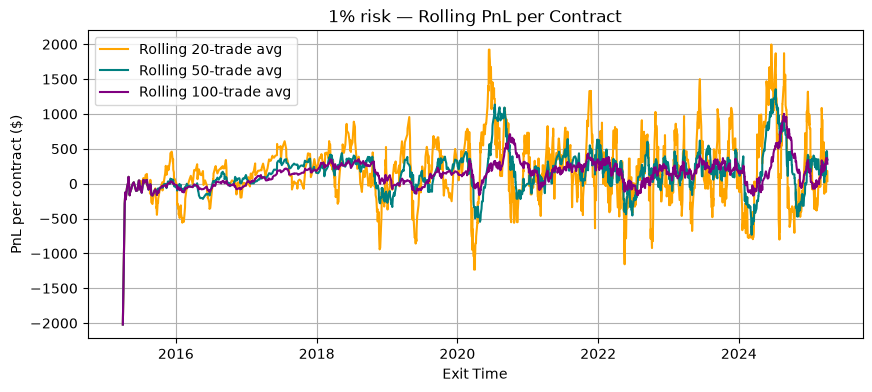

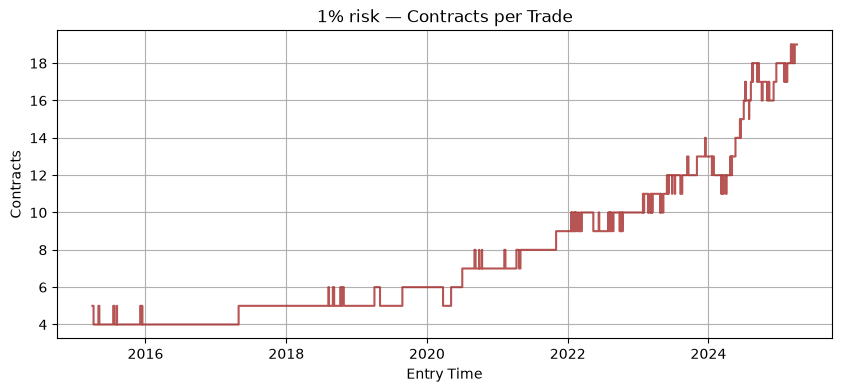

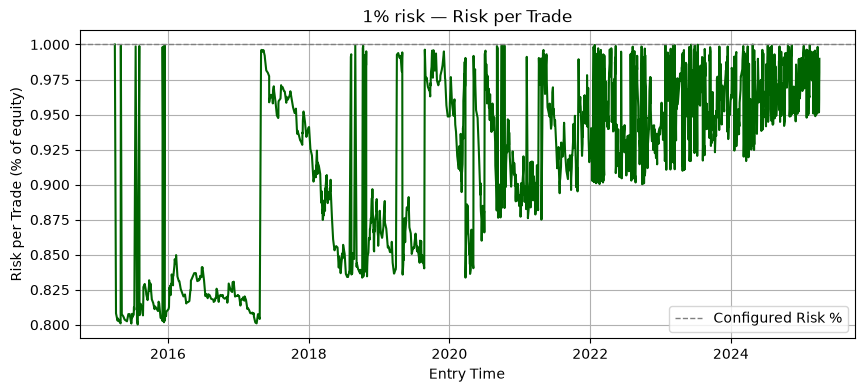

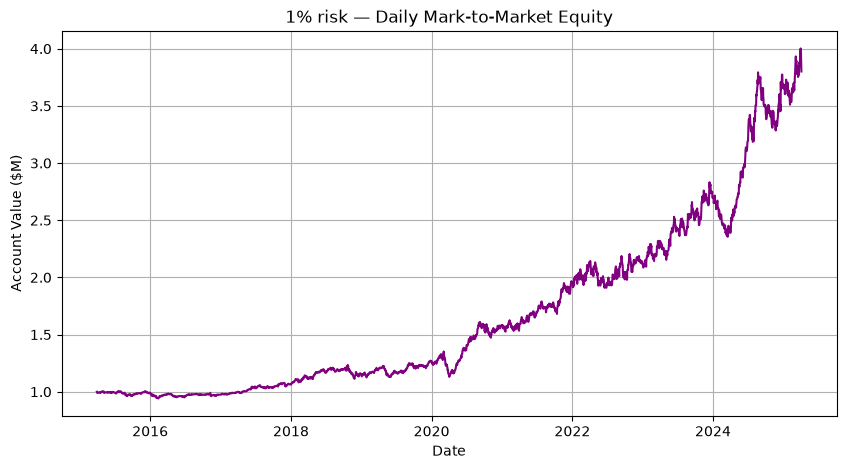

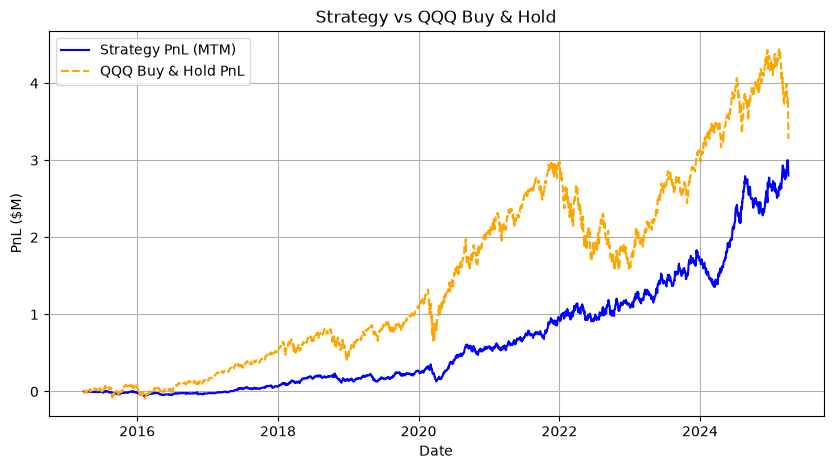

In [4]:
plot_backtest(bt_1pct, title_prefix='1% risk')

qqq_equity = align_benchmark(qqq, bt_1pct.equity.index, BASE.initial_capital)
plot_vs_benchmark(bt_1pct, qqq_equity)

In [5]:
split_date = pd.Timestamp('2022-01-31')  # rules frozen in early 2022

equities = {
    'NQ 1% risk (stop entry)': bt_1pct.equity,
    'NQ 2% risk (stop entry)': bt_2pct.equity,
    'NQ 1% risk (close entry, legacy)': bt_legacy.equity,
    'QQQ Buy & Hold': qqq_equity,
}

print('Overall (daily mark-to-market equity):')
display(format_metrics(metrics_table(equities)))

print(f'Pre-split (before {split_date.date()}):')
display(format_metrics(metrics_table({k: v[v.index < split_date] for k, v in equities.items()})))

print(f'Post-split (from {split_date.date()}):')
display(format_metrics(metrics_table({k: v[v.index >= split_date] for k, v in equities.items()})))

Overall (daily mark-to-market equity):


,Sharpe,Volatility,Max Drawdown %,Max Drawdown $,CAGR
NQ 1% risk (stop entry),1.02,14.12%,16.82%,"-507,995",14.26%
NQ 2% risk (stop entry),1.02,29.43%,32.12%,"-3,475,150",29.26%
"NQ 1% risk (close entry, legacy)",1.11,14.11%,17.73%,"-470,265",15.74%
QQQ Buy & Hold,0.77,22.11%,35.12%,"-1,402,731",15.61%


Pre-split (before 2022-01-31):


,Sharpe,Volatility,Max Drawdown %,Max Drawdown $,CAGR
NQ 1% risk (stop entry),1.03,10.27%,16.42%,"-221,955",10.58%
NQ 2% risk (stop entry),1.00,21.80%,32.12%,"-585,380",21.50%
"NQ 1% risk (close entry, legacy)",0.87,10.29%,17.73%,"-243,690",8.75%
QQQ Buy & Hold,0.97,21.23%,28.56%,"-663,011",20.03%


Post-split (from 2022-01-31):


,Sharpe,Volatility,Max Drawdown %,Max Drawdown $,CAGR
NQ 1% risk (stop entry),1.10,20.03%,16.82%,"-507,995",22.12%
NQ 2% risk (stop entry),1.13,41.33%,31.72%,"-3,475,150",46.38%
"NQ 1% risk (close entry, legacy)",1.49,19.98%,16.30%,"-470,265",31.89%
QQQ Buy & Hold,0.35,23.85%,29.56%,"-1,173,939",5.63%


In [6]:
# How much of the edge depends on the entry convention?
comparison = pd.DataFrame({
    'stop entry': bt_1pct.trades.groupby('direction')['pnl_per_contract'].agg(['mean', 'count']).unstack(),
    'close entry (legacy)': bt_legacy.trades.groupby('direction')['pnl_per_contract'].agg(['mean', 'count']).unstack(),
}).round(2)
print('PnL per contract by direction and entry convention:')
display(comparison)

PnL per contract by direction and entry convention:


stop entry  close entry (legacy)
      direction                                  
mean  long           332.75                400.21
      short           15.80                -23.53
count long           877.00                875.00
      short          848.00                861.00